<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Box Plots**


Estimated time needed: **45** minutes


In this lab, you will focus on the visualization of data. The dataset will be provided through an RDBMS, and you will need to use SQL queries to extract the required data.


## Objectives


In this lab you will perform the following:


-   Visualize the distribution of data.

-   Visualize the relationship between two features.

-   Visualize data composition and comparisons using box plots.


### Setup: Connecting to the Database


#### 1. Download the Database File


In [13]:
!wget https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/QR9YeprUYhOoLafzlLspAw/survey-results-public.sqlite

Resolving cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud (cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud)... 169.63.118.104
Connecting to cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud (cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud)|169.63.118.104|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 211415040 (202M) [application/octet-stream]
Saving to: ‘survey-results-public.sqlite.2’

survey-results-publ 100%[===================>] 201.62M  5.64MB/s    in 29s     
2026-08-21 10:03:21 (6.98 MB/s) - ‘survey-results-public.sqlite.2’ saved [211415040/211415040]


#### 2. Connect to the Database


**Install the needed libraries**


In [14]:
!pip install pandas

In [15]:
!pip install matplotlib

In [16]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

# Connect to the SQLite database
conn = sqlite3.connect('survey-results-public.sqlite')


## Demo: Basic SQL Queries


#### Demo 1: Count the Number of Rows in the Table


In [17]:
QUERY = "SELECT COUNT(*) FROM main"
df = pd.read_sql_query(QUERY, conn)
print(df)


   COUNT(*)
0     65437

#### Demo 2: List All Tables


In [18]:
QUERY = """
SELECT name as Table_Name 
FROM sqlite_master 
WHERE type = 'table'
"""
pd.read_sql_query(QUERY, conn)


,Table_Name
0,main


#### Demo 3: Group Data by Age


In [19]:
QUERY = """
SELECT Age, COUNT(*) as count 
FROM main 
GROUP BY Age 
ORDER BY Age
"""
df_age = pd.read_sql_query(QUERY, conn)
print(df_age)


                  Age  count
0     18-24 years old  14098
1     25-34 years old  23911
2     35-44 years old  14942
3     45-54 years old   6249
4     55-64 years old   2575
5   65 years or older    772
6   Prefer not to say    322
7  Under 18 years old   2568

## Visualizing Data


### Task 1: Visualizing the Distribution of Data


**1. Box Plot of `CompTotal` (Total Compensation)**


Use a box plot to analyze the distribution and outliers in total compensation.


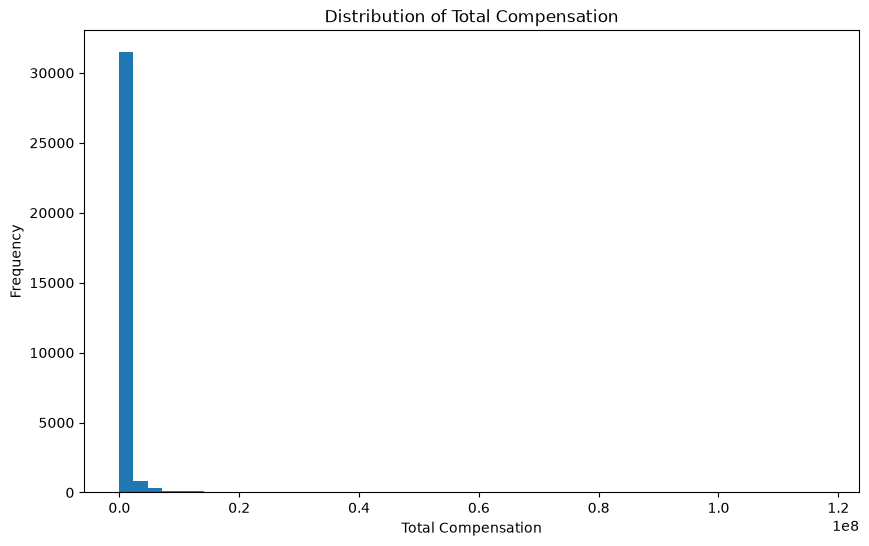

In [20]:
# your code goes here
# Get CompTotal from database
QUERY = """
SELECT CompTotal
FROM main
"""

df_comp = pd.read_sql_query(QUERY, conn)

# Remove missing values
comp = df_comp["CompTotal"].dropna()

# Remove extreme values
comp = comp[comp < comp.quantile(0.99)]

# Plot histogram
plt.figure(figsize=(10, 6))

plt.hist(comp, bins=50)

plt.title("Distribution of Total Compensation")
plt.xlabel("Total Compensation")
plt.ylabel("Frequency")

plt.show()

**2. Box Plot of Age (converted to numeric values)**


Convert the `Age` column into numerical values and visualize the distribution.


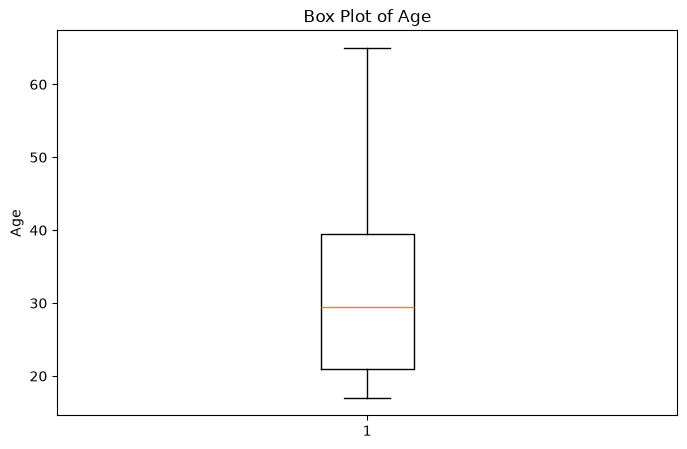

In [22]:
# your code goes here
# Convert Age categories to numeric values
# Get Age from the database
QUERY = """
SELECT Age
FROM main
"""

df_age = pd.read_sql_query(QUERY, conn)

# Convert Age categories to numeric values
age_mapping = {
    "Under 18 years old": 17,
    "18-24 years old": 21,
    "25-34 years old": 29.5,
    "35-44 years old": 39.5,
    "45-54 years old": 49.5,
    "55-64 years old": 59.5,
    "65 years or older": 65,
    "Prefer not to say": None
}

age_numeric = df_age["Age"].map(age_mapping).dropna()

# Create box plot
plt.figure(figsize=(8, 5))

plt.boxplot(age_numeric)

plt.title("Box Plot of Age")
plt.ylabel("Age")

plt.show()

### Task 2: Visualizing Relationships in Data


**1. Box Plot of `CompTotal` Grouped by Age Groups:**


Visualize the distribution of compensation across different age groups.


<Figure size 1200x600 with 0 Axes>

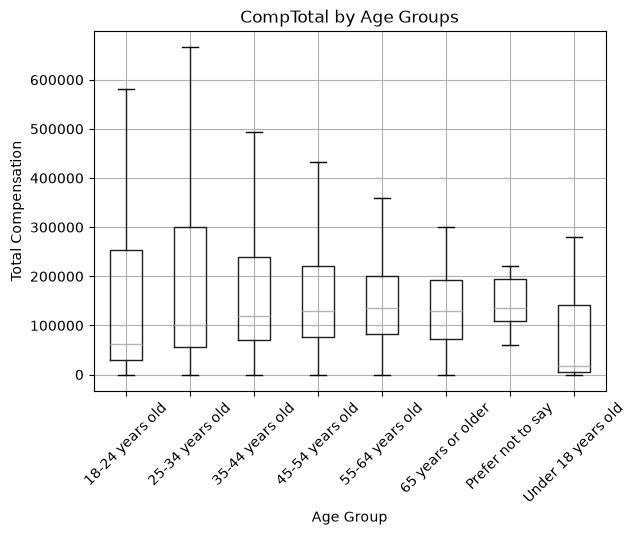

In [24]:
# your code goes here
# Get Age and CompTotal from the database
# Get Age and CompTotal from the database
QUERY = """
SELECT Age, CompTotal
FROM main
"""

df_comp_age = pd.read_sql_query(QUERY, conn)

# Remove missing values
df_comp_age = df_comp_age.dropna(subset=["Age", "CompTotal"])

# Create box plot
plt.figure(figsize=(12, 6))

df_comp_age.boxplot(
    column="CompTotal",
    by="Age",
    showfliers=False
)

plt.title("CompTotal by Age Groups")
plt.suptitle("")
plt.xlabel("Age Group")
plt.ylabel("Total Compensation")
plt.xticks(rotation=45)

plt.show()

**2. Box Plot of `CompTotal` Grouped by Job Satisfaction (`JobSatPoints_6`):**


Examine how compensation varies based on job satisfaction levels.


<Figure size 1200x600 with 0 Axes>

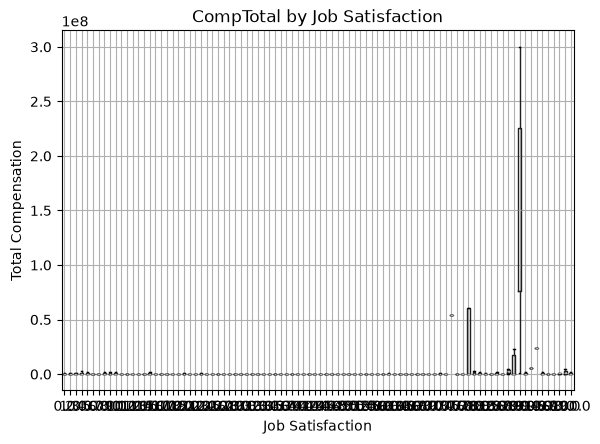

In [29]:
# your code goes here
# Get CompTotal and JobSatPoints_6 from the database
QUERY = """
SELECT CompTotal, JobSatPoints_6
FROM main
"""

df_jobsat = pd.read_sql_query(QUERY, conn)

# Remove missing values
df_jobsat = df_jobsat.dropna(
    subset=["CompTotal", "JobSatPoints_6"]
)

# Create box plot
plt.figure(figsize=(12, 6))

df_jobsat.boxplot(
    column="CompTotal",
    by="JobSatPoints_6",
    showfliers=False
)

plt.title("CompTotal by Job Satisfaction")
plt.suptitle("")
plt.xlabel("Job Satisfaction")
plt.ylabel("Total Compensation")

plt.show()

### Task 3: Visualizing the Composition of Data


**1. Box Plot of `ConvertedCompYearly` for the Top 5 Developer Types:**


Analyze compensation across the top 5 developer roles.


<Figure size 1200x600 with 0 Axes>

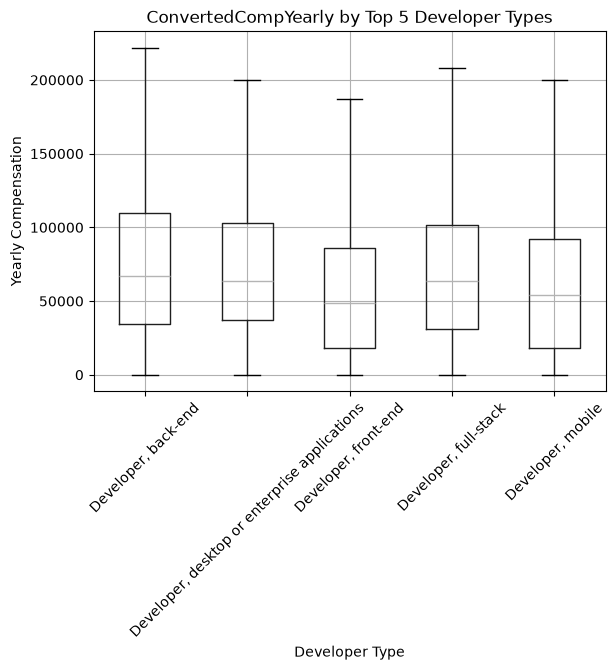

In [30]:
# your code goes here
# Get Developer Type and ConvertedCompYearly
QUERY = """
SELECT DevType, ConvertedCompYearly
FROM main
"""

df_dev = pd.read_sql_query(QUERY, conn)

# Remove missing values
df_dev = df_dev.dropna(
    subset=["DevType", "ConvertedCompYearly"]
)

# Find the top 5 developer types
top_5_devtypes = df_dev["DevType"].value_counts().head(5).index

# Keep only the top 5
df_top5 = df_dev[
    df_dev["DevType"].isin(top_5_devtypes)
]

# Create box plot
plt.figure(figsize=(12, 6))

df_top5.boxplot(
    column="ConvertedCompYearly",
    by="DevType",
    showfliers=False
)

plt.title("ConvertedCompYearly by Top 5 Developer Types")
plt.suptitle("")
plt.xlabel("Developer Type")
plt.ylabel("Yearly Compensation")
plt.xticks(rotation=45)

plt.show()

**2. Box Plot of `CompTotal` for the Top 5 Countries:**


Analyze compensation across respondents from the top 5 countries.


<Figure size 1200x600 with 0 Axes>

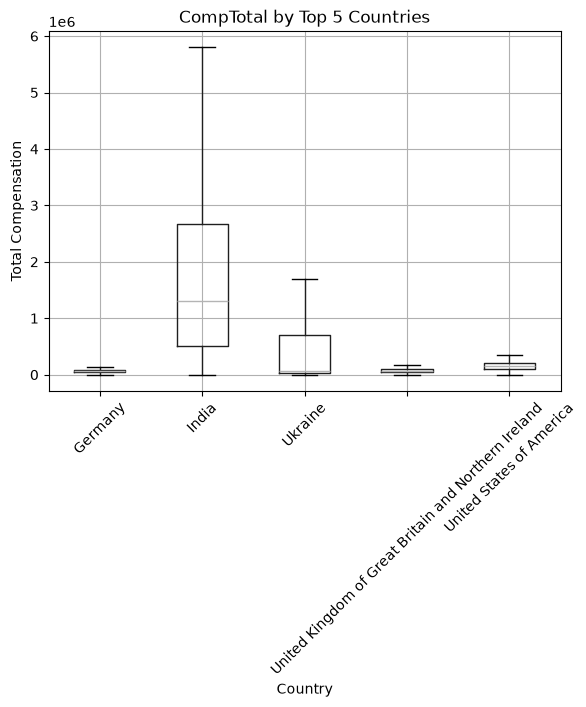

In [31]:
# your code goes here
# Get Country and CompTotal
QUERY = """
SELECT Country, CompTotal
FROM main
"""

df_country = pd.read_sql_query(QUERY, conn)

# Remove missing values
df_country = df_country.dropna(
    subset=["Country", "CompTotal"]
)

# Find the top 5 countries
top_5_countries = df_country["Country"].value_counts().head(5).index

# Keep only the top 5 countries
df_top5_country = df_country[
    df_country["Country"].isin(top_5_countries)
]

# Create box plot
plt.figure(figsize=(12, 6))

df_top5_country.boxplot(
    column="CompTotal",
    by="Country",
    showfliers=False
)

plt.title("CompTotal by Top 5 Countries")
plt.suptitle("")
plt.xlabel("Country")
plt.ylabel("Total Compensation")
plt.xticks(rotation=45)

plt.show()

### Task 4: Visualizing Comparison of Data


**1. Box Plot of CompTotal Across Employment Types:**


Analyze compensation for different employment types.


<Figure size 1200x600 with 0 Axes>

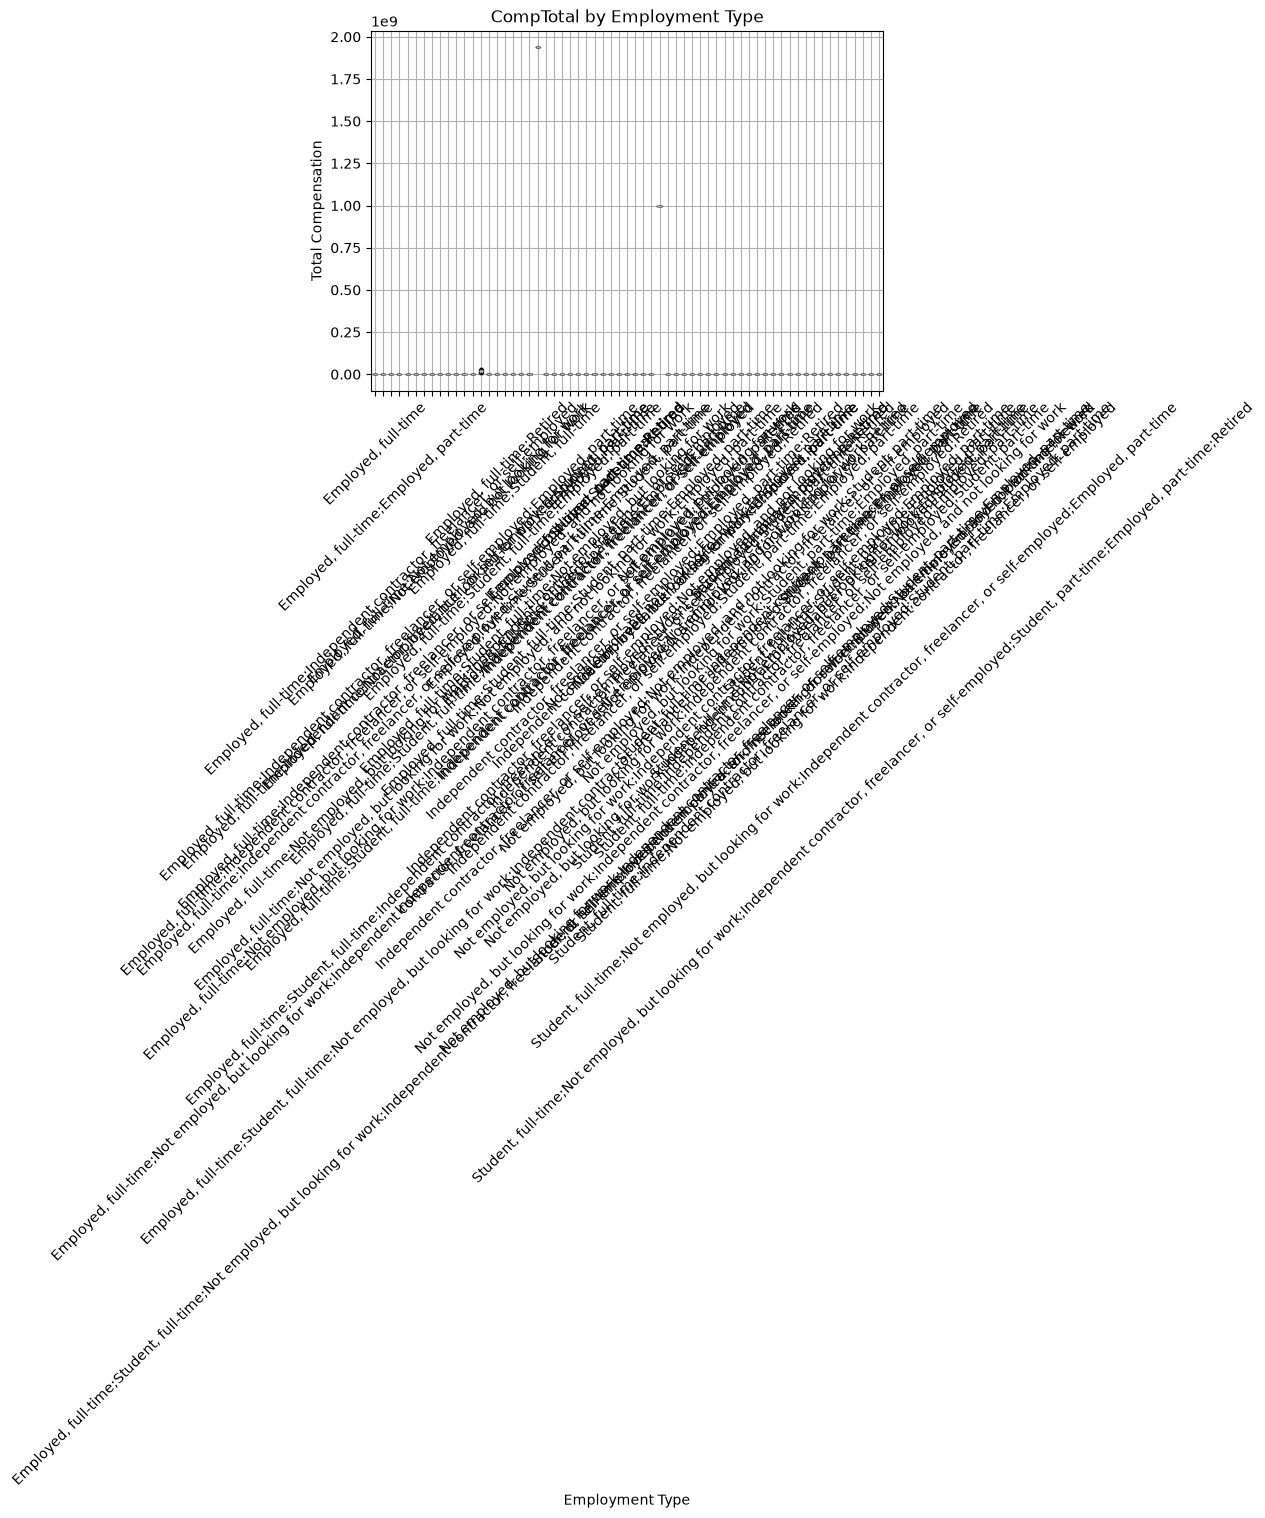

In [32]:
# your code goes here
# Get Employment and CompTotal
QUERY = """
SELECT Employment, CompTotal
FROM main
"""

df_employment = pd.read_sql_query(QUERY, conn)

# Remove missing values
df_employment = df_employment.dropna(
    subset=["Employment", "CompTotal"]
)

# Create box plot
plt.figure(figsize=(12, 6))

df_employment.boxplot(
    column="CompTotal",
    by="Employment",
    showfliers=False
)

plt.title("CompTotal by Employment Type")
plt.suptitle("")
plt.xlabel("Employment Type")
plt.ylabel("Total Compensation")
plt.xticks(rotation=45)

plt.show()

**2. Box Plot of `YearsCodePro` by Job Satisfaction (`JobSatPoints_6`):**


Examine the distribution of professional coding years by job satisfaction levels.


<Figure size 1200x600 with 0 Axes>

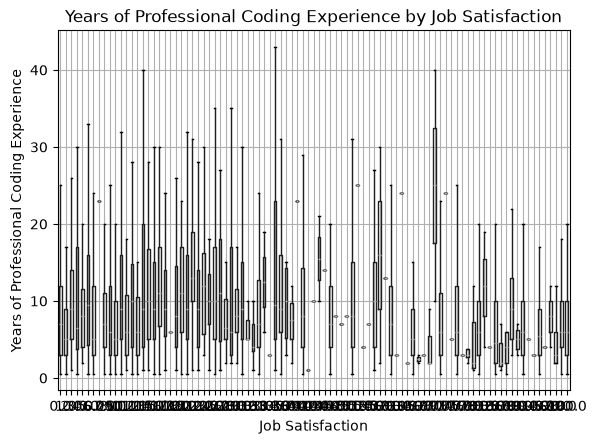

In [34]:
# your code goes here
# Get YearsCodePro and JobSatPoints_6
QUERY = """
SELECT YearsCodePro, JobSatPoints_6
FROM main
"""

df_code_sat = pd.read_sql_query(QUERY, conn)

# Convert YearsCodePro to numeric values
df_code_sat["YearsCodePro"] = df_code_sat["YearsCodePro"].replace({
    "Less than 1 year": 0.5,
    "More than 50 years": 51
})

df_code_sat["YearsCodePro"] = pd.to_numeric(
    df_code_sat["YearsCodePro"],
    errors="coerce"
)

# Remove missing values
df_code_sat = df_code_sat.dropna(
    subset=["YearsCodePro", "JobSatPoints_6"]
)

# Create box plot
plt.figure(figsize=(12, 6))

df_code_sat.boxplot(
    column="YearsCodePro",
    by="JobSatPoints_6",
    showfliers=False
)

plt.title("Years of Professional Coding Experience by Job Satisfaction")
plt.suptitle("")
plt.xlabel("Job Satisfaction")
plt.ylabel("Years of Professional Coding Experience")

plt.show()

### Final Step: Close the Database Connection


After completing the lab, close the connection to the SQLite database:


In [35]:
conn.close()

## Summary


In this lab, you used box plots to visualize various aspects of the dataset, focusing on:

- Visualize distributions of compensation and age.

- Explore relationships between compensation, job satisfaction, and professional coding experience.

- Analyze data composition across developer roles and countries.

- Compare compensation across employment types and satisfaction levels.

Box plots provided clear insights into the spread, outliers, and central tendencies of various features in the dataset.


## Authors:
Ayushi Jain


### Other Contributors:
- Rav Ahuja
- Lakshmi Holla
- Malika


<!--## Change Log
|Date (YYYY-MM-DD)|Version|Changed By|Change Description|
|-|-|-|-|               
|2024-10-07|1.2|Madhusudan Moole|Reviewed and updated lab|                                                                                      
|2024-10-06|1.0|Raghul Ramesh|Created lab|-->


Copyright © IBM Corporation. All rights reserved.
